In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG19, MobileNetV2
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.layers import Dense, Flatten, Dropout, GlobalAveragePooling2D
from tensorflow.keras.callbacks import EarlyStopping
from google.colab import files
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

In [ ]:
import os
import zipfile
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import imutils
import time
import pandas as pd

In [ ]:
uploaded = files.upload()

Saving cell_images.zip to cell_images (1).zip


In [ ]:
!unzip -o cell_images.zip -d /content/cell_images

Streaming output truncated to the last 5000 lines.
  inflating: /content/cell_images/cell_images/Uninfected/C236ThinF_IMG_20151127_102428_cell_116.png  
  inflating: /content/cell_images/cell_images/Uninfected/C236ThinF_IMG_20151127_102428_cell_118.png  
  inflating: /content/cell_images/cell_images/Uninfected/C236ThinF_IMG_20151127_102428_cell_126.png  
  inflating: /content/cell_images/cell_images/Uninfected/C236ThinF_IMG_20151127_102428_cell_134.png  
  inflating: /content/cell_images/cell_images/Uninfected/C236ThinF_IMG_20151127_102428_cell_141.png  
  inflating: /content/cell_images/cell_images/Uninfected/C236ThinF_IMG_20151127_102428_cell_168.png  
  inflating: /content/cell_images/cell_images/Uninfected/C236ThinF_IMG_20151127_102428_cell_175.png  
  inflating: /content/cell_images/cell_images/Uninfected/C236ThinF_IMG_20151127_102428_cell_183.png  
  inflating: /content/cell_images/cell_images/Uninfected/C236ThinF_IMG_20151127_102428_cell_221.png  
  inflating: /content/cell_imag

In [ ]:
zip_file_name = list(uploaded.keys())[0]
zip_file_name

'cell_images (1).zip'

In [ ]:
EXTRACT_DIR = "./malaria_dataset"
print(f"Extracting {zip_file_name} to {EXTRACT_DIR}...")
with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)
print("Extraction complete!")


Extracting cell_images (1).zip to ./malaria_dataset...
Extraction complete!


In [ ]:
subfolders = os.listdir(EXTRACT_DIR)
print("Detected contents:", subfolders)

Detected contents: ['cell_images']


In [ ]:
if len(subfolders) == 1 and os.path.isdir(os.path.join(EXTRACT_DIR, subfolders[0])):
    DATA_DIR = os.path.join(EXTRACT_DIR, subfolders[0])
else:
    DATA_DIR = EXTRACT_DIR

In [ ]:
print(os.listdir('/content/cell_images'))

['cell_images']


In [ ]:
dataset_path = '/content/malaria_dataset/cell_images/cell_images'

In [ ]:
dataset_path = '/content/cell_images/cell_images'
df=[]
for label in os.listdir(dataset_path):
    folder = os.path.join(dataset_path, label)

    if os.path.isdir(folder):
        count = len([
            f for f in os.listdir(folder)
            if f.endswith('.png')
        ])

        df.append({
            'Class': label,
            'Count': count
        })

In [ ]:
dt=pd.DataFrame(df)

In [ ]:
dt

,Class,Count
0,Uninfected,13779
1,Parasitized,13779


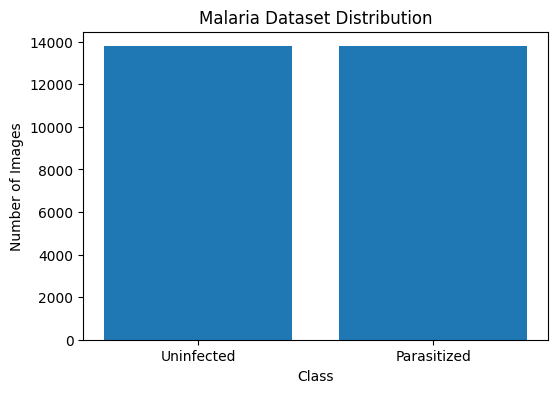

In [ ]:
plt.figure(figsize=(6,4))

plt.bar(dt['Class'], dt['Count'])

plt.xlabel('Class')
plt.ylabel('Number of Images')
plt.title('Malaria Dataset Distribution')

plt.show()

In [ ]:
IMG_SIZE = (124, 124)
BATCH_SIZE = 32

In [ ]:
datagen = ImageDataGenerator(rescale=1./255,validation_split=0.2,rotation_range=20,width_shift_range=0.1,height_shift_range=0.1,horizontal_flip=True,vertical_flip=True)

train_generator = datagen.flow_from_directory(DATA_DIR,target_size=IMG_SIZE,batch_size=BATCH_SIZE,class_mode='binary',subset='training',shuffle=True)

val_generator = datagen.flow_from_directory(DATA_DIR,target_size=IMG_SIZE,batch_size=BATCH_SIZE,class_mode='binary',subset='validation',shuffle=False)

Found 22048 images belonging to 2 classes.
Found 5510 images belonging to 2 classes.


In [ ]:
def build_vgg19(input_shape):
    base_model = VGG19(weights='imagenet', include_top=False, input_shape=input_shape)
    for layer in base_model.layers:
        layer.trainable = False

    x = Flatten()(base_model.output)
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.5)(x)
    output = Dense(1, activation='sigmoid')(x)

    return Model(inputs=base_model.input, outputs=output, name="Malaria_VGG19")

In [ ]:
def build_mobilenet(input_shape):
    base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=input_shape)
    for layer in base_model.layers:
        layer.trainable = False

    x = GlobalAveragePooling2D()(base_model.output)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.3)(x)
    output = Dense(1, activation='sigmoid')(x)

    return Model(inputs=base_model.input, outputs=output, name="Malaria_MobileNetV2")

In [ ]:
input_shape = (IMG_SIZE[0], IMG_SIZE[1], 3)
epochs = 10

In [ ]:
vgg19_model = build_vgg19(input_shape)
vgg19_model.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])

In [ ]:
print("\n--- Training VGG19 ---")
vgg19_history = vgg19_model.fit(train_generator, validation_data=val_generator, epochs=epochs)


--- Training VGG19 ---
Epoch 1/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 178s 250ms/step - accuracy: 0.8296 - loss: 0.3776 - val_accuracy: 0.8702 - val_loss: 0.3113
Epoch 2/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 168s 244ms/step - accuracy: 0.8799 - loss: 0.2902 - val_accuracy: 0.8857 - val_loss: 0.2748
Epoch 3/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 163s 237ms/step - accuracy: 0.8914 - loss: 0.2677 - val_accuracy: 0.8951 - val_loss: 0.2741
Epoch 4/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 169s 245ms/step - accuracy: 0.8985 - loss: 0.2519 - val_accuracy: 0.8947 - val_loss: 0.2591
Epoch 5/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 169s 245ms/step - accuracy: 0.8985 - loss: 0.2531 - val_accuracy: 0.8967 - val_loss: 0.2484
Epoch 6/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 164s 238ms/step - accuracy: 0.9008 - loss: 0.2392 - val_accuracy: 0.9054 - val_loss: 0.2412
Epoch 7/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 162s 235ms/step - accuracy: 0.9070 - loss: 0.2363 - val_accuracy: 0.8926 - val_loss: 0.2484
Epoch 8/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 167s 243ms/s

In [ ]:
test_loss, test_acc = vgg19_model.evaluate(val_generator)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

173/173 ━━━━━━━━━━━━━━━━━━━━ 33s 191ms/step - accuracy: 0.9098 - loss: 0.2216
Test Loss: 0.22164592146873474
Test Accuracy: 0.9098003506660461


In [ ]:
base_model = tf.keras.applications.VGG19(weights='imagenet',include_top=False,input_shape=(224, 224, 3))

In [ ]:
early_stopping = EarlyStopping(monitor='val_loss',patience=2,restore_best_weights=True)

history = vgg19_model.fit(train_generator,validation_data=val_generator,epochs=12,callbacks=[early_stopping])

Epoch 1/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 168s 244ms/step - accuracy: 0.9106 - loss: 0.2265 - val_accuracy: 0.9036 - val_loss: 0.2338
Epoch 2/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 163s 236ms/step - accuracy: 0.9103 - loss: 0.2254 - val_accuracy: 0.9054 - val_loss: 0.2293
Epoch 3/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 164s 239ms/step - accuracy: 0.9131 - loss: 0.2187 - val_accuracy: 0.8984 - val_loss: 0.2402
Epoch 4/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 161s 234ms/step - accuracy: 0.9133 - loss: 0.2198 - val_accuracy: 0.9020 - val_loss: 0.2287
Epoch 5/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 160s 233ms/step - accuracy: 0.9151 - loss: 0.2166 - val_accuracy: 0.9080 - val_loss: 0.2259
Epoch 6/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 160s 233ms/step - accuracy: 0.9164 - loss: 0.2196 - val_accuracy: 0.9120 - val_loss: 0.2183
Epoch 7/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 165s 240ms/step - accuracy: 0.9175 - loss: 0.2132 - val_accuracy: 0.9058 - val_loss: 0.2226
Epoch 8/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 162s 235ms/step - accuracy: 0.9148 -

In [ ]:
mobilenet_model = build_mobilenet(input_shape)
mobilenet_model.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])

/tmp/ipykernel_21456/4186385797.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=input_shape)


In [ ]:
mobilenet_history = mobilenet_model.fit(train_generator, validation_data=val_generator, epochs=epochs)

Epoch 1/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 167s 225ms/step - accuracy: 0.8896 - loss: 0.2676 - val_accuracy: 0.9136 - val_loss: 0.2288
Epoch 2/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 150s 218ms/step - accuracy: 0.9249 - loss: 0.2026 - val_accuracy: 0.9162 - val_loss: 0.2179
Epoch 3/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 148s 215ms/step - accuracy: 0.9313 - loss: 0.1891 - val_accuracy: 0.9234 - val_loss: 0.2003
Epoch 4/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 150s 217ms/step - accuracy: 0.9351 - loss: 0.1809 - val_accuracy: 0.9194 - val_loss: 0.2065
Epoch 5/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 149s 216ms/step - accuracy: 0.9359 - loss: 0.1783 - val_accuracy: 0.9185 - val_loss: 0.2131
Epoch 6/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 148s 214ms/step - accuracy: 0.9351 - loss: 0.1739 - val_accuracy: 0.9249 - val_loss: 0.2076
Epoch 7/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 147s 213ms/step - accuracy: 0.9377 - loss: 0.1673 - val_accuracy: 0.9225 - val_loss: 0.2026
Epoch 8/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 148s 214ms/step - accuracy: 0.9386 -

In [ ]:
test_loss, test_acc = mobilenet_model.evaluate(val_generator)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

173/173 ━━━━━━━━━━━━━━━━━━━━ 30s 174ms/step - accuracy: 0.9283 - loss: 0.1865
Test Loss: 0.18652556836605072
Test Accuracy: 0.9283121824264526


In [ ]:
base_model = tf.keras.applications.MobileNetV2(weights='imagenet',include_top=False,input_shape=(224, 224, 3))

In [ ]:
early_stop = EarlyStopping(monitor='val_loss',patience=2,restore_best_weights=True)

mobilenet_history_es = mobilenet_model.fit(train_generator,validation_data=val_generator,epochs=12,callbacks=[early_stop])

Epoch 1/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 146s 212ms/step - accuracy: 0.9395 - loss: 0.1653 - val_accuracy: 0.9258 - val_loss: 0.1992
Epoch 2/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 145s 211ms/step - accuracy: 0.9406 - loss: 0.1634 - val_accuracy: 0.9260 - val_loss: 0.1989
Epoch 3/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 148s 215ms/step - accuracy: 0.9404 - loss: 0.1614 - val_accuracy: 0.9285 - val_loss: 0.1912
Epoch 4/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 146s 212ms/step - accuracy: 0.9419 - loss: 0.1648 - val_accuracy: 0.9265 - val_loss: 0.1878
Epoch 5/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 147s 214ms/step - accuracy: 0.9414 - loss: 0.1623 - val_accuracy: 0.9312 - val_loss: 0.1888
Epoch 6/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 146s 211ms/step - accuracy: 0.9415 - loss: 0.1604 - val_accuracy: 0.9263 - val_loss: 0.1960


Generating predictions on validation dataset...
173/173 ━━━━━━━━━━━━━━━━━━━━ 33s 187ms/step
173/173 ━━━━━━━━━━━━━━━━━━━━ 36s 185ms/step

 1. MODEL COMPACTNESS (NUMBER OF PARAMETERS)
VGG19 Total Parameters:       21,204,545
MobileNetV2 Total Parameters: 2,422,081
Reduction Factor:             MobileNetV2 is 8.8x smaller!

 2. DETAILED CLASSIFICATION REPORTS

[VGG19 CLASSIFICATION REPORT]
              precision    recall  f1-score   support

 Parasitized       0.95      0.85      0.90      2755
  Uninfected       0.86      0.96      0.91      2755

    accuracy                           0.90      5510
   macro avg       0.91      0.90      0.90      5510
weighted avg       0.91      0.90      0.90      5510


[MOBILENETV2 CLASSIFICATION REPORT]
              precision    recall  f1-score   support

 Parasitized       0.94      0.91      0.93      2755
  Uninfected       0.92      0.94      0.93      2755

    accuracy                           0.93      5510
   macro avg       0.93     

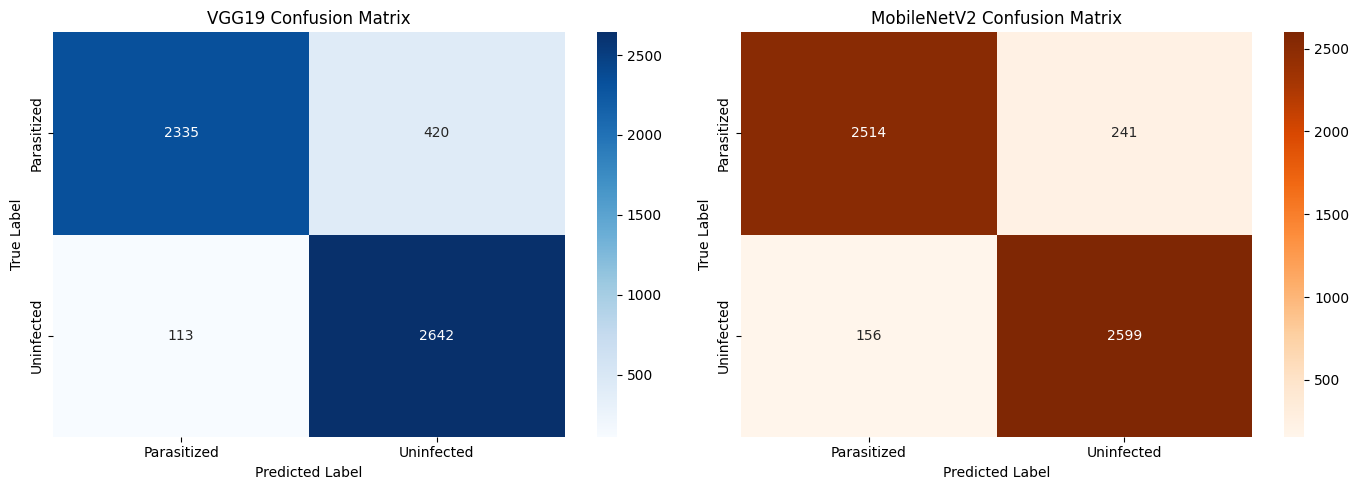

In [ ]:
print("Generating predictions on validation dataset...")

# Reset generator to ensure correct ordering of labels
val_generator.reset()
y_true = val_generator.classes  # Real ground truth labels (0: Parasitized, 1: Uninfected)

# Predict with VGG19
start_time = time.time()
vgg19_preds_raw = vgg19_model.predict(val_generator, verbose=1)
vgg19_preds = (vgg19_preds_raw > 0.5).astype(int).flatten()

# Predict with MobileNetV2
start_time_mb = time.time()
mobilenet_preds_raw = mobilenet_model.predict(val_generator, verbose=1)
mobilenet_preds = (mobilenet_preds_raw > 0.5).astype(int).flatten()

print("\n" + "="*60)
print(" 1. MODEL COMPACTNESS (NUMBER OF PARAMETERS)")
print("="*60)
vgg_params = vgg19_model.count_params()
mb_params = mobilenet_model.count_params()
print(f"VGG19 Total Parameters:       {vgg_params:,}")
print(f"MobileNetV2 Total Parameters: {mb_params:,}")
print(f"Reduction Factor:             MobileNetV2 is {vgg_params/mb_params:.1f}x smaller!")


print("\n" + "="*60)
print(" 2. DETAILED CLASSIFICATION REPORTS")
print("="*60)

target_names = list(val_generator.class_indices.keys()) # ['Parasitized', 'Uninfected']

print("\n[VGG19 CLASSIFICATION REPORT]")
print(classification_report(y_true, vgg19_preds, target_names=target_names))

print("\n[MOBILENETV2 CLASSIFICATION REPORT]")
print(classification_report(y_true, mobilenet_preds, target_names=target_names))


cm_vgg = confusion_matrix(y_true, vgg19_preds)
cm_mb = confusion_matrix(y_true, mobilenet_preds)

# Plot side-by-side matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot VGG19 Confusion Matrix
sns.heatmap(cm_vgg, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=target_names, yticklabels=target_names)
axes[0].set_title('VGG19 Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Plot MobileNetV2 Confusion Matrix
sns.heatmap(cm_mb, annot=True, fmt='d', cmap='Oranges', ax=axes[1],
            xticklabels=target_names, yticklabels=target_names)
axes[1].set_title('MobileNetV2 Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()


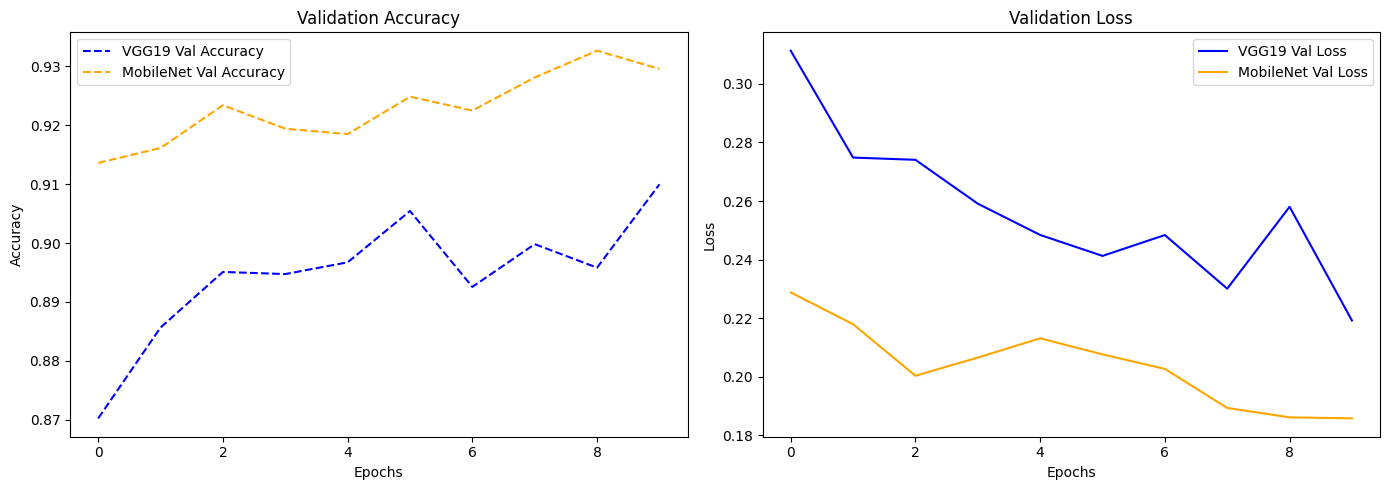

In [ ]:
plt.figure(figsize=(14, 5))
# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(vgg19_history.history['val_accuracy'], label='VGG19 Val Accuracy', color='blue', linestyle='--')
plt.plot(mobilenet_history.history['val_accuracy'], label='MobileNet Val Accuracy', color='orange', linestyle='--')
plt.title('Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(vgg19_history.history['val_loss'], label='VGG19 Val Loss', color='blue')
plt.plot(mobilenet_history.history['val_loss'], label='MobileNet Val Loss', color='orange')
plt.title('Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

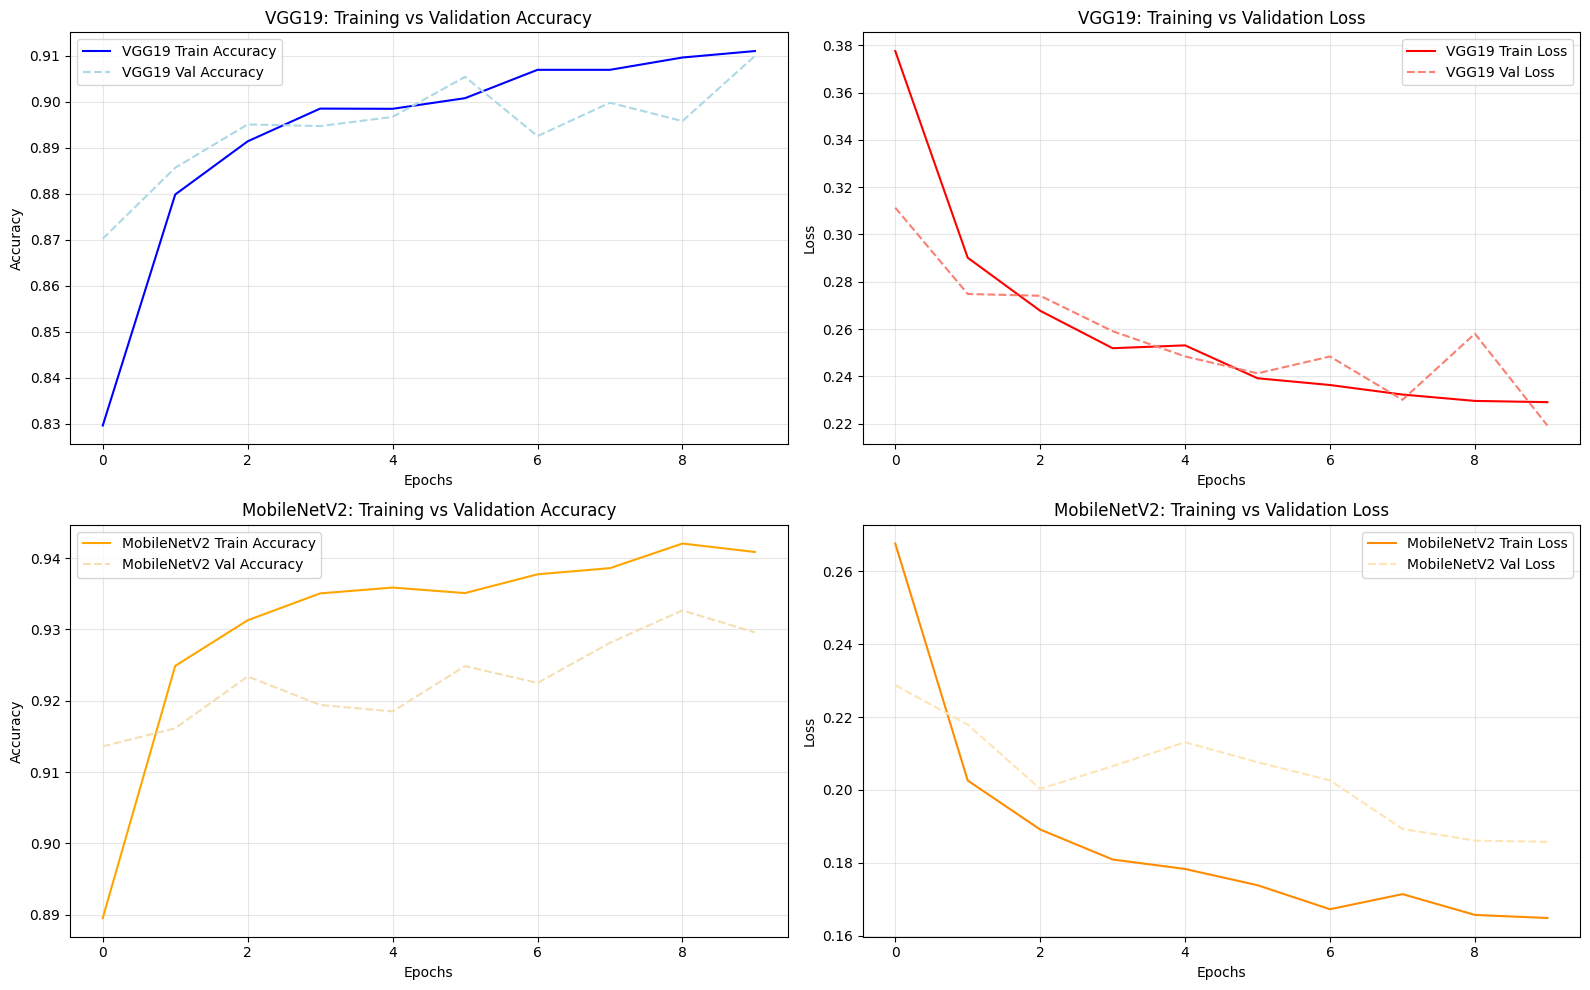

In [ ]:
import matplotlib.pyplot as plt

# Create a side-by-side comparison of Training vs Validation for both models
plt.figure(figsize=(16, 10))

# --- VGG19 Accuracy ---
plt.subplot(2, 2, 1)
plt.plot(vgg19_history.history['accuracy'], label='VGG19 Train Accuracy', color='blue', linestyle='-')
plt.plot(vgg19_history.history['val_accuracy'], label='VGG19 Val Accuracy', color='lightblue', linestyle='--')
plt.title('VGG19: Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

# --- VGG19 Loss ---
plt.subplot(2, 2, 2)
plt.plot(vgg19_history.history['loss'], label='VGG19 Train Loss', color='red', linestyle='-')
plt.plot(vgg19_history.history['val_loss'], label='VGG19 Val Loss', color='salmon', linestyle='--')
plt.title('VGG19: Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# --- MobileNetV2 Accuracy ---
plt.subplot(2, 2, 3)
plt.plot(mobilenet_history.history['accuracy'], label='MobileNetV2 Train Accuracy', color='orange', linestyle='-')
plt.plot(mobilenet_history.history['val_accuracy'], label='MobileNetV2 Val Accuracy', color='wheat', linestyle='--')
plt.title('MobileNetV2: Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

# --- MobileNetV2 Loss ---
plt.subplot(2, 2, 4)
plt.plot(mobilenet_history.history['loss'], label='MobileNetV2 Train Loss', color='darkorange', linestyle='-')
plt.plot(mobilenet_history.history['val_loss'], label='MobileNetV2 Val Loss', color='moccasin', linestyle='--')
plt.title('MobileNetV2: Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

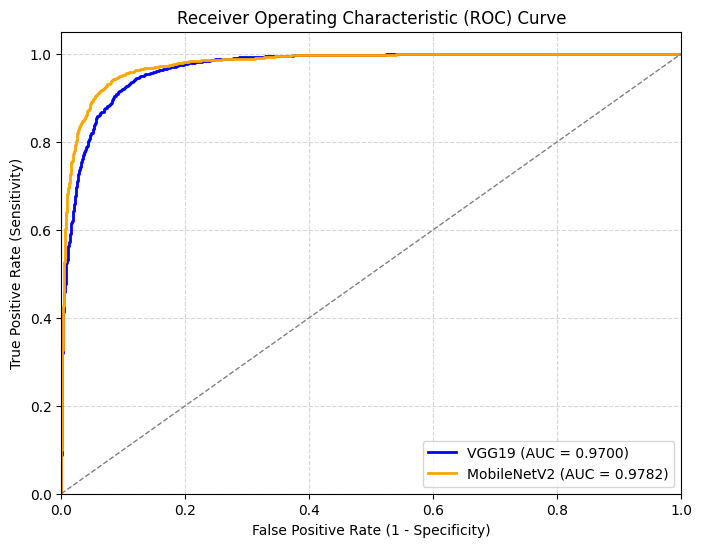

In [ ]:
from sklearn.metrics import roc_curve, auc

# Calculate ROC curves and AUC scores
fpr_vgg, tpr_vgg, _ = roc_curve(y_true, vgg19_preds_raw)
roc_auc_vgg = auc(fpr_vgg, tpr_vgg)

fpr_mb, tpr_mb, _ = roc_curve(y_true, mobilenet_preds_raw)
roc_auc_mb = auc(fpr_mb, tpr_mb)

# Plot the ROC curves
plt.figure(figsize=(8, 6))
plt.plot(fpr_vgg, tpr_vgg, color='blue', lw=2, label=f'VGG19 (AUC = {roc_auc_vgg:.4f})')
plt.plot(fpr_mb, tpr_mb, color='orange', lw=2, label=f'MobileNetV2 (AUC = {roc_auc_mb:.4f})')

# Plot random guess line
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
import time
import numpy as np

# Ensure the validation generator is reset
val_generator.reset()
num_images = val_generator.n

print(f"Evaluating inference speed over {num_images} images...\n")

# Measure VGG19 Inference Time
start_vgg = time.time()
_ = vgg19_model.predict(val_generator, verbose=0)
end_vgg = time.time()
total_time_vgg = end_vgg - start_vgg
avg_time_vgg = (total_time_vgg / num_images) * 1000  # in milliseconds

# Measure MobileNetV2 Inference Time
start_mb = time.time()
_ = mobilenet_model.predict(val_generator, verbose=0)
end_mb = time.time()
total_time_mb = end_mb - start_mb
avg_time_mb = (total_time_mb / num_images) * 1000  # in milliseconds

# Print Results
print("="*50)
print("             INFERENCE TIME COMPARISON            ")
print("="*50)
print(f"VGG19:")
print(f"  Total Inference Time: {total_time_vgg:.2f} seconds")
print(f"  Average Per-Image:    {avg_time_vgg:.4f} ms")
print(f"\nMobileNetV2:")
print(f"  Total Inference Time: {total_time_mb:.2f} seconds")
print(f"  Average Per-Image:    {avg_time_mb:.4f} ms")
print("-"*50)
print(f"Speedup: MobileNetV2 is {total_time_vgg / total_time_mb:.2f}x faster than VGG19!")
print("="*50)

Evaluating inference speed over 5510 images...

             INFERENCE TIME COMPARISON            
VGG19:
  Total Inference Time: 34.87 seconds
  Average Per-Image:    6.3276 ms

MobileNetV2:
  Total Inference Time: 29.50 seconds
  Average Per-Image:    5.3534 ms
--------------------------------------------------
Speedup: MobileNetV2 is 1.18x faster than VGG19!


            ROC-AUC VARIANCE & STABILITY REPORT            
VGG19 ROC-AUC:
  Mean AUC:            0.97001
  Variance:            3.92e-06
  Standard Deviation:  0.00198
  95% Confidence Int:  [0.96605, 0.97379]

MobileNetV2 ROC-AUC:
  Mean AUC:            0.97822
  Variance:            2.58e-06
  Standard Deviation:  0.00161
  95% Confidence Int:  [0.97501, 0.98144]


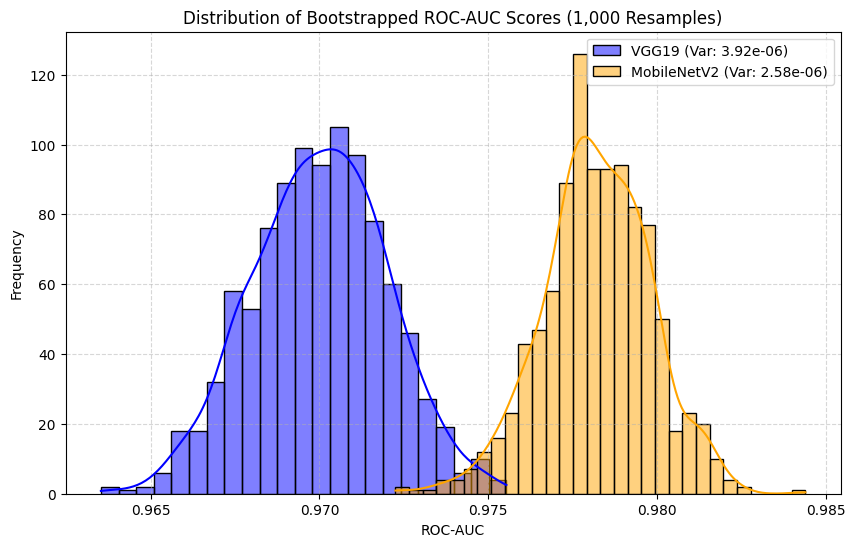

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc
from sklearn.utils import resample

# Configure bootstrapping parameters
n_bootstraps = 1000
bootstrapped_auc_vgg = []
bootstrapped_auc_mb = []

# Perform bootstrapping
np.random.seed(42)
indices = np.arange(len(y_true))

for i in range(n_bootstraps):
    # Resample validation indices with replacement
    boot_idx = resample(indices, replace=True)

    # VGG19 Bootstrapped AUC
    fpr_v, tpr_v, _ = roc_curve(y_true[boot_idx], vgg19_preds_raw[boot_idx])
    boot_auc_v = auc(fpr_v, tpr_v)
    bootstrapped_auc_vgg.append(boot_auc_v)

    # MobileNetV2 Bootstrapped AUC
    fpr_m, tpr_m, _ = roc_curve(y_true[boot_idx], mobilenet_preds_raw[boot_idx])
    boot_auc_m = auc(fpr_m, tpr_m)
    bootstrapped_auc_mb.append(boot_auc_m)

# Calculate Statistics
var_vgg = np.var(bootstrapped_auc_vgg)
var_mb = np.var(bootstrapped_auc_mb)
std_vgg = np.std(bootstrapped_auc_vgg)
std_mb = np.std(bootstrapped_auc_mb)

ci_vgg = np.percentile(bootstrapped_auc_vgg, [2.5, 97.5])
ci_mb = np.percentile(bootstrapped_auc_mb, [2.5, 97.5])

# Print Summary
print("="*60)
print("            ROC-AUC VARIANCE & STABILITY REPORT            ")
print("="*60)
print(f"VGG19 ROC-AUC:")
print(f"  Mean AUC:            {np.mean(bootstrapped_auc_vgg):.5f}")
print(f"  Variance:            {var_vgg:.2e}")
print(f"  Standard Deviation:  {std_vgg:.5f}")
print(f"  95% Confidence Int:  [{ci_vgg[0]:.5f}, {ci_vgg[1]:.5f}]")
print(f"\nMobileNetV2 ROC-AUC:")
print(f"  Mean AUC:            {np.mean(bootstrapped_auc_mb):.5f}")
print(f"  Variance:            {var_mb:.2e}")
print(f"  Standard Deviation:  {std_mb:.5f}")
print(f"  95% Confidence Int:  [{ci_mb[0]:.5f}, {ci_mb[1]:.5f}]")
print("="*60)

# Plot Distributions
plt.figure(figsize=(10, 6))
sns.histplot(bootstrapped_auc_vgg, kde=True, color='blue', label=f'VGG19 (Var: {var_vgg:.2e})', alpha=0.5)
sns.histplot(bootstrapped_auc_mb, kde=True, color='orange', label=f'MobileNetV2 (Var: {var_mb:.2e})', alpha=0.5)
plt.title('Distribution of Bootstrapped ROC-AUC Scores (1,000 Resamples)')
plt.xlabel('ROC-AUC')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()